### RNA (60660 features)
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

In [3]:
common_samples = np.load("/home/data/data_YM313112004/TLS_model/match_sample/common_samples.npy", allow_pickle=True)

from pymaftools import PivotTable
rna_table = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table_full.sqlite")
all_table = rna_table.subset(samples=common_samples)
all_table

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table_full.sqlite


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
TSPAN6,4.388644,4.917403,4.479179,4.603798,5.008845,5.341861,4.992265,4.859065,4.099127,4.732394,...,4.643233,4.552352,4.949689,5.176478,5.628916,4.733381,4.694958,4.498410,4.881718,3.821343
TNMD,0.000000,0.000000,0.000000,0.609093,0.000000,0.000000,0.086920,0.159112,0.095047,0.000000,...,1.665484,0.780730,0.066537,0.062260,0.222063,0.170181,0.151859,0.000000,0.000000,2.266966
DPM1,5.883112,6.133742,7.164674,6.580254,6.337492,6.310934,5.977124,6.301736,5.734428,6.582860,...,6.085140,6.231790,6.420782,6.288002,6.270172,6.530811,6.519344,6.347317,6.466725,6.856362
SCYL3,3.045128,2.954103,2.350469,3.776809,2.812046,3.047643,4.047364,3.502509,3.151096,2.878745,...,2.726373,3.037804,2.882956,2.696216,3.208486,2.670999,2.558513,2.455518,3.112300,3.189809
C1orf112,1.680459,1.683696,2.598460,2.437174,1.515763,1.803103,1.619929,2.478532,1.541217,2.155037,...,1.282203,1.458224,2.069496,1.723733,2.142446,1.458697,1.644595,1.762391,1.824523,2.203608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC008763.4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.027579,0.000000,0.063227
AL592295.6,2.974438,3.236615,3.438745,4.076910,3.159016,3.699185,3.997301,3.404113,3.393540,3.770713,...,3.431021,3.394857,3.357960,3.050275,3.012336,3.054987,2.831756,2.578287,3.773131,2.783079
AC006486.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [4]:
selected_type = (
    pd.Series(all_table.feature_metadata["gene_type"])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(selected_type)

gene_type
protein_coding                        19962
lncRNA                                16901
processed_pseudogene                  10167
unprocessed_pseudogene                 2614
misc_RNA                               2212
snRNA                                  1901
miRNA                                  1881
TEC                                    1057
snoRNA                                  943
transcribed_unprocessed_pseudogene      939
transcribed_processed_pseudogene        500
rRNA_pseudogene                         497
IG_V_pseudogene                         187
IG_V_gene                               145
transcribed_unitary_pseudogene          138
TR_V_gene                               106
unitary_pseudogene                       98
TR_J_gene                                79
scaRNA                                   49
polymorphic_pseudogene                   48
rRNA                                     47
IG_D_gene                                37
TR_V_pseudogene       

#### Feature Selection

- Protein Coding

In [5]:
# 只取 protein coding genes (19962 genes)
table = all_table.subset(features=all_table.feature_metadata["gene_type"] == "protein_coding")
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
TSPAN6,4.388644,4.917403,4.479179,4.603798,5.008845,5.341861,4.992265,4.859065,4.099127,4.732394,...,4.643233,4.552352,4.949689,5.176478,5.628916,4.733381,4.694958,4.498410,4.881718,3.821343
TNMD,0.000000,0.000000,0.000000,0.609093,0.000000,0.000000,0.086920,0.159112,0.095047,0.000000,...,1.665484,0.780730,0.066537,0.062260,0.222063,0.170181,0.151859,0.000000,0.000000,2.266966
DPM1,5.883112,6.133742,7.164674,6.580254,6.337492,6.310934,5.977124,6.301736,5.734428,6.582860,...,6.085140,6.231790,6.420782,6.288002,6.270172,6.530811,6.519344,6.347317,6.466725,6.856362
SCYL3,3.045128,2.954103,2.350469,3.776809,2.812046,3.047643,4.047364,3.502509,3.151096,2.878745,...,2.726373,3.037804,2.882956,2.696216,3.208486,2.670999,2.558513,2.455518,3.112300,3.189809
C1orf112,1.680459,1.683696,2.598460,2.437174,1.515763,1.803103,1.619929,2.478532,1.541217,2.155037,...,1.282203,1.458224,2.069496,1.723733,2.142446,1.458697,1.644595,1.762391,1.824523,2.203608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AL451106.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AC008763.4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.027579,0.000000,0.063227
AC006486.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


- Pseudoautosomal regions

In [6]:
# 移除包含 "PAR_Y" 的行
non_par_mask = ~table.feature_metadata["ensg_name"].str.contains("PAR_Y", na=False)
table = table.subset(features=non_par_mask)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
TSPAN6,4.388644,4.917403,4.479179,4.603798,5.008845,5.341861,4.992265,4.859065,4.099127,4.732394,...,4.643233,4.552352,4.949689,5.176478,5.628916,4.733381,4.694958,4.498410,4.881718,3.821343
TNMD,0.000000,0.000000,0.000000,0.609093,0.000000,0.000000,0.086920,0.159112,0.095047,0.000000,...,1.665484,0.780730,0.066537,0.062260,0.222063,0.170181,0.151859,0.000000,0.000000,2.266966
DPM1,5.883112,6.133742,7.164674,6.580254,6.337492,6.310934,5.977124,6.301736,5.734428,6.582860,...,6.085140,6.231790,6.420782,6.288002,6.270172,6.530811,6.519344,6.347317,6.466725,6.856362
SCYL3,3.045128,2.954103,2.350469,3.776809,2.812046,3.047643,4.047364,3.502509,3.151096,2.878745,...,2.726373,3.037804,2.882956,2.696216,3.208486,2.670999,2.558513,2.455518,3.112300,3.189809
C1orf112,1.680459,1.683696,2.598460,2.437174,1.515763,1.803103,1.619929,2.478532,1.541217,2.155037,...,1.282203,1.458224,2.069496,1.723733,2.142446,1.458697,1.644595,1.762391,1.824523,2.203608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AL451106.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AC008763.4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.027579,0.000000,0.063227
AC006486.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


- Sex Chromosomes

In [7]:
# # 讀入 GTF (只取非註解行)
# gtf = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode.v36.annotation.gtf", sep="\t", comment="#", header=None)
# gtf.columns = ["chr","source","feature","start","end","score","strand","phase","additional_info"]

# # 只保留 gene 層級
# gencode = gtf[gtf["feature"] == "gene"].copy()

# # 從 additional_info 欄位解析 gene_type 和 gene_name
# def get_info(attr, key):
#     for entry in attr.split(";"):
#         entry = entry.strip()  # 移除頭尾指定字符
#         if entry.startswith(key + " "):
#             return entry.split(" ")[1].replace('"','')
#     return None

# gencode["gene_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_id"))
# gencode["gene_type"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_type"))
# gencode["gene_name"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_name"))
# gencode["level"] = gencode["additional_info"].apply(lambda x: get_info(x, "level"))
# gencode["hgnc_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "hgnc_id"))
# gencode["havana_gene"] = gencode["additional_info"].apply(lambda x: get_info(x, "havana_gene"))
# gencode.drop(columns=["feature"], inplace=True)
# gencode.to_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index=False)

In [8]:
gencode = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index_col=False)
gencode = gencode[~gencode["gene_id"].str.contains("PAR_Y", na=False)]  # 移除包含 "PAR_Y" 的行
gencode.index = gencode["gene_name"]

# 使用 gene_id 進行合併
merged_gencode = pd.merge(
    table.feature_metadata,
    gencode,
    left_on="ensg_name",  
    right_on="gene_id",
    how="left"  # 使用左合併，保留 table.feature_metadata 的所有行
)
merged_gencode.index = merged_gencode["gene_name_x"]

# Add feature metadata
table = table.add_feature_metadata(merged_gencode, fill_value=np.nan, force=True)
table.feature_metadata

  ['WASH6P', 'ZBED1', 'GTPBP6', 'P2RY8', 'SHOX']...
Overwriting existing columns: ['change', 'padj', 'ensg_name', 'stat', 'pvalue', 'baseMean', 'lfcSE', 'log2FoldChange']


,gene_name,gene_type,baseMean,change,ensg_name,gene_name_x,gene_type_x,lfcSE,log2FoldChange,padj,...,score,strand,phase,additional_info,gene_id,gene_type_y,gene_name_y,level,hgnc_id,havana_gene
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,A1BG,protein_coding,7.346755,NOT,ENSG00000121410.12,A1BG,protein_coding,0.200506,-0.097785,0.757038,...,.,-,.,"gene_id ""ENSG00000121410.12""; gene_type ""prote...",ENSG00000121410.12,protein_coding,A1BG,1.0,HGNC:5,OTTHUMG00000183507.3
A1CF,A1CF,protein_coding,478.132311,NOT,ENSG00000148584.15,A1CF,protein_coding,0.252681,-0.179771,0.627076,...,.,-,.,"gene_id ""ENSG00000148584.15""; gene_type ""prote...",ENSG00000148584.15,protein_coding,A1CF,2.0,HGNC:24086,OTTHUMG00000018240.6
A2M,A2M,protein_coding,31495.076867,NOT,ENSG00000175899.15,A2M,protein_coding,0.117290,0.580328,0.000023,...,.,-,.,"gene_id ""ENSG00000175899.15""; gene_type ""prote...",ENSG00000175899.15,protein_coding,A2M,2.0,HGNC:7,OTTHUMG00000150267.7
A2ML1,A2ML1,protein_coding,428.067886,NOT,ENSG00000166535.20,A2ML1,protein_coding,0.405207,0.366715,0.520275,...,.,+,.,"gene_id ""ENSG00000166535.20""; gene_type ""prote...",ENSG00000166535.20,protein_coding,A2ML1,2.0,HGNC:23336,OTTHUMG00000128499.9
A3GALT2,A3GALT2,protein_coding,1.881195,NOT,ENSG00000184389.9,A3GALT2,protein_coding,0.242955,-0.205162,0.551841,...,.,-,.,"gene_id ""ENSG00000184389.9""; gene_type ""protei...",ENSG00000184389.9,protein_coding,A3GALT2,2.0,HGNC:30005,OTTHUMG00000004125.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,ZYG11A,protein_coding,5.580330,NOT,ENSG00000203995.10,ZYG11A,protein_coding,0.254633,-0.280670,0.418943,...,.,+,.,"gene_id ""ENSG00000203995.10""; gene_type ""prote...",ENSG00000203995.10,protein_coding,ZYG11A,2.0,HGNC:32058,OTTHUMG00000008923.5
ZYG11B,ZYG11B,protein_coding,1512.450754,NOT,ENSG00000162378.13,ZYG11B,protein_coding,0.063913,0.210497,0.005452,...,.,+,.,"gene_id ""ENSG00000162378.13""; gene_type ""prote...",ENSG00000162378.13,protein_coding,ZYG11B,2.0,HGNC:25820,OTTHUMG00000008938.2
ZYX,ZYX,protein_coding,10395.791254,NOT,ENSG00000159840.16,ZYX,protein_coding,0.093538,-0.065173,0.635735,...,.,+,.,"gene_id ""ENSG00000159840.16""; gene_type ""prote...",ENSG00000159840.16,protein_coding,ZYX,1.0,HGNC:13200,OTTHUMG00000023822.11


In [9]:
# Filter sex chromosome genes (19026 genes)
clean_table = pd.Series(table.feature_metadata["chr"]).dropna()
mask = clean_table.apply(lambda x: x not in ["chrX", "chrY"])
non_sex_chr = mask[mask].index.tolist()
table = table.subset(features=non_sex_chr)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,0.144177,0.197111,0.060462,0.158725,0.049770,0.133827,0.095992,0.138028,0.138159,0.074916,...,0.226632,0.291839,0.231678,0.091124,0.085968,0.157691,0.193330,0.299127,0.024178,0.152768
A1CF,0.967390,1.610228,0.730314,1.489851,1.175365,1.480575,0.515712,3.005436,1.373231,0.023752,...,2.143916,2.434455,1.610275,2.266996,1.327227,1.242511,2.486972,0.173639,0.959993,0.523261
A2M,8.720515,8.484469,7.540605,8.409315,8.878823,7.876755,7.952907,8.866145,8.019636,6.383099,...,9.260183,9.107143,8.721742,9.061168,8.759337,8.867650,9.178502,7.389550,6.583868,7.864132
A2ML1,1.692070,0.064193,5.397255,0.849439,3.823454,4.497287,1.572114,0.620117,0.267356,4.715723,...,0.534062,0.110631,0.474462,0.678883,0.080248,0.550605,0.350158,4.997229,0.492725,1.208392
A3GALT2,0.000000,0.000000,0.115832,0.000000,0.000000,0.361656,0.237931,0.224287,0.000000,0.700440,...,0.130931,0.483777,0.268195,0.172999,0.641823,0.124725,0.000000,0.000000,0.482642,0.432211
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.000000,0.077790,0.051581,0.338339,0.042504,0.086920,0.055335,0.068877,0.045583,0.184217,...,0.029559,0.096936,0.236462,0.019915,0.049491,0.082703,0.049491,0.069152,0.020627,0.362330
ZYG11B,3.565366,3.814253,3.877067,4.007196,3.586308,4.313405,3.596494,4.003800,3.058091,2.844185,...,4.014944,4.165663,3.572987,3.958499,3.978873,3.906265,4.043651,3.546845,2.906352,3.947171
ZYX,8.233354,7.914015,8.826262,8.016946,8.172009,7.704481,8.251627,8.114179,7.772493,7.862774,...,8.260751,7.829933,7.871752,8.942100,7.946248,8.173957,8.622784,8.427931,7.754568,7.730280


In [10]:
# DEG 定義: p.adj < 0.01 & |log2FC| > 1 
# pc genes 跑 DESeq
# deg_list = fc_hugo[fc_hugo['change'].isin(['UP', 'DOWN'])].index.tolist()
# print("DEGs:", len(deg_list))  # 1155 個 DEGs

deg_list_pc = table.feature_metadata[table.feature_metadata['change'].isin(['UP', 'DOWN'])].index.tolist()
print("DEGs in protein coding genes:", len(deg_list_pc))  # 483 個 DEGs

DEGs in protein coding genes: 474


#### Exploratory Visualization

In [11]:
# 對 dataset 進行 z-score normalization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
table_scaled = pd.DataFrame(scaler.fit_transform(table.T).T, index=table.index, columns=table.columns)
table_scaled = PivotTable(table_scaled)
table_scaled.feature_metadata = table.feature_metadata
table_scaled.sample_metadata = table.sample_metadata
table_scaled

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,-0.136351,0.086267,-0.488421,-0.075168,-0.533388,-0.179881,-0.338998,-0.162211,-0.161659,-0.427633,...,0.210422,0.484658,0.231644,-0.359469,-0.381153,-0.079518,0.070368,0.515309,-0.641020,-0.100222
A1CF,-0.643191,-0.061099,-0.857865,-0.170100,-0.454869,-0.178499,-1.052187,1.202269,-0.275701,-1.497660,...,0.422158,0.685243,-0.061056,0.533608,-0.317357,-0.394068,0.732797,-1.361936,-0.649890,-1.045352
A2M,0.512394,0.284058,-0.628977,0.211358,0.665531,-0.303807,-0.230142,0.653268,-0.165593,-1.748675,...,1.034435,0.886394,0.513581,0.841920,0.549948,0.654723,0.955421,-0.775098,-1.554464,-0.316018
A2ML1,0.272077,-0.697731,2.479441,-0.229921,1.541848,1.943284,0.200613,-0.366539,-0.576696,2.073418,...,-0.417806,-0.670066,-0.453313,-0.331529,-0.688166,-0.407951,-0.527367,2.241125,-0.442433,-0.016074
A3GALT2,-0.981593,-0.981593,-0.284798,-0.981593,-0.981593,1.193968,0.449692,0.367619,-0.981593,3.231938,...,-0.193972,1.928593,0.631747,0.059094,2.879329,-0.231302,-0.981593,-0.981593,1.921763,1.618395
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,-0.695891,-0.134854,-0.323878,1.744282,-0.389341,-0.069008,-0.296807,-0.199134,-0.367138,0.632720,...,-0.482706,0.003236,1.009524,-0.552257,-0.338949,-0.099422,-0.338949,-0.197150,-0.547127,1.917309
ZYG11B,-0.261705,0.153322,0.258067,0.475060,-0.226783,0.985675,-0.209798,0.469398,-1.107601,-1.464297,...,0.487982,0.739309,-0.248997,0.393858,0.427831,0.306756,0.535850,-0.292589,-1.360632,0.374967
ZYX,0.751210,0.337402,1.519517,0.470783,0.671718,0.065881,0.774889,0.596779,0.154014,0.271003,...,0.786712,0.228445,0.282637,1.669623,0.379171,0.674242,1.255844,1.003348,0.130785,0.099313


Cleaned matrix shape: (18513, 172)
Removed rows: 513, removed cols: 0


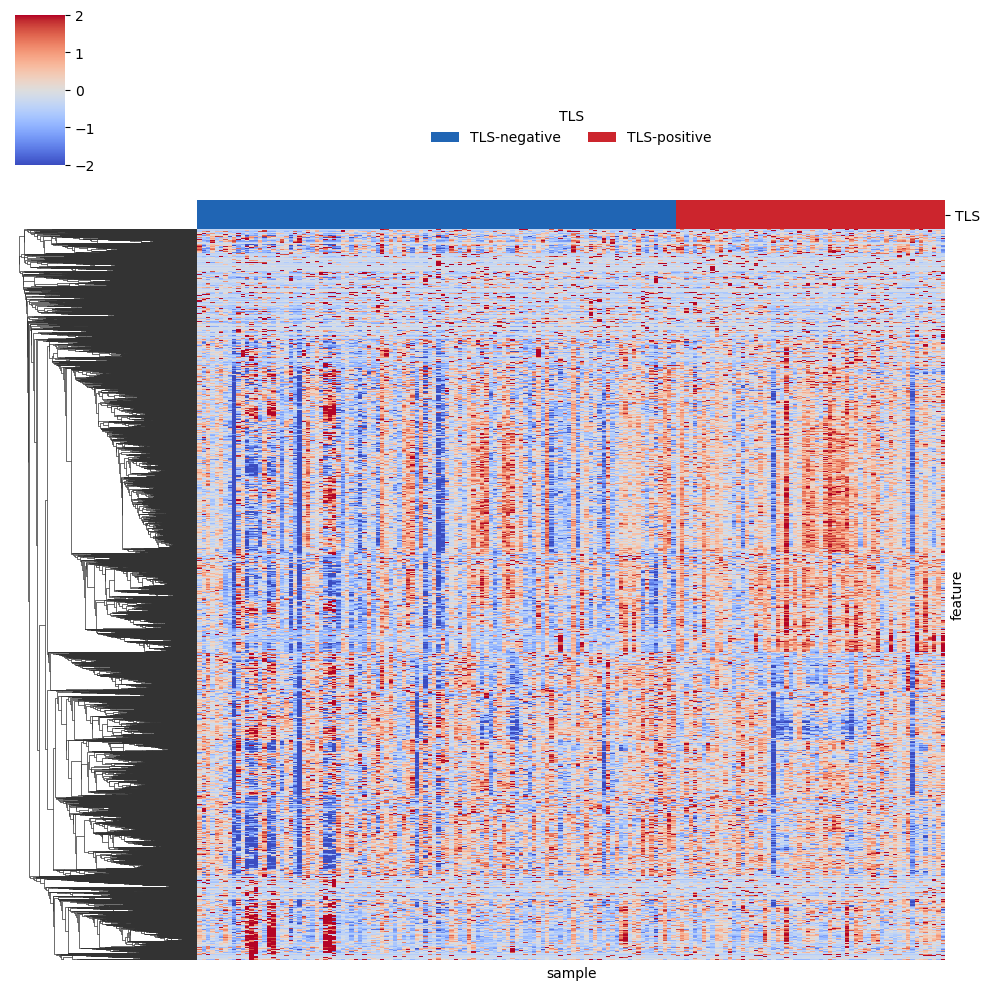

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

# 移除含 var=0（correlation 無法定義）or NaN 的基因列/樣本欄，避免 correlation 無法計算
mat = pd.DataFrame(table_scaled).replace([np.inf, -np.inf], np.nan)
mat = mat.loc[mat.notna().all(axis=1), mat.notna().all(axis=0)]

row_var = mat.var(axis=1)
col_var = mat.var(axis=0)
mat = mat.loc[row_var > 0, col_var > 0]
print(f"Cleaned matrix shape: {mat.shape}")
print(f"Removed rows: {(row_var <= 0).sum()}, removed cols: {(col_var <= 0).sum()}")

# 依 TLS status 排序欄位
tls_series = table_scaled.sample_metadata.loc[mat.columns, "TLS"].astype(int)
sorted_cols = tls_series.sort_values(ascending=True).index
mat = mat.loc[:, sorted_cols]
tls_series = tls_series.loc[sorted_cols]

# TLS 欄位色帶（依排序後欄位對齊）
tls_palette = {0: "#2065B4", 1: "#CC252D"}
col_colors = tls_series.map(tls_palette)

g = sns.clustermap(mat, cmap="coolwarm", metric="correlation", col_colors=col_colors, col_cluster=False,
                   cbar_pos=(0.02, 0.83, 0.05, 0.15), vmax=2, vmin=-2, xticklabels=False, yticklabels=False) 

# 加上 TLS legend
handles = [
    Patch(facecolor="#2065B4", edgecolor="none", label="TLS-negative"),
    Patch(facecolor="#CC252D", edgecolor="none", label="TLS-positive")
]
g.ax_heatmap.legend(handles=handles, title="TLS", loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.18))

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

# 移除含 var=0（correlation 無法定義）or NaN 的基因列/樣本欄，避免 correlation 無法計算
mat = pd.DataFrame(table_scaled).replace([np.inf, -np.inf], np.nan)
mat = mat.loc[mat.notna().all(axis=1), mat.notna().all(axis=0)]

row_var = mat.var(axis=1)
col_var = mat.var(axis=0)
mat = mat.loc[row_var > 0, col_var > 0]
print(f"Cleaned matrix shape: {mat.shape}")
print(f"Removed rows: {(row_var <= 0).sum()}, removed cols: {(col_var <= 0).sum()}")

In [ ]:
# clustermap: 保留 row clustering，但不顯示 row dendrogram；feature 在左、legend + colorbar 在右
g = sns.clustermap(
    mat,
    cmap="coolwarm",
    metric="correlation",
    col_colors=col_colors,
    col_cluster=False,
    row_cluster=True,
    figsize=(10, 8),
    dendrogram_ratio=(0.001, 0.12),   # row dendrogram 幾乎不佔空間，但仍進行 clustering
    cbar_pos=(0.97, 0.1, 0.02, 0.6),  # (left, bottom, width, height)
    vmax=2,
    vmin=-2,
    xticklabels=False,
    yticklabels=False
 )

# 隱藏 row dendrogram（不影響 row clustering 的排序結果）
g.ax_row_dendrogram.set_visible(False)

# feature 軸資訊放左邊
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel("features")
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.yaxis.tick_left()

# TLS legend 放右側
handles = [
    Patch(facecolor="#2065B4", edgecolor="none", label="TLS−"),
    Patch(facecolor="#CC252D", edgecolor="none", label="TLS+")
]
g.ax_heatmap.legend(
    handles=handles,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1, 1.02),
    frameon=False
 )

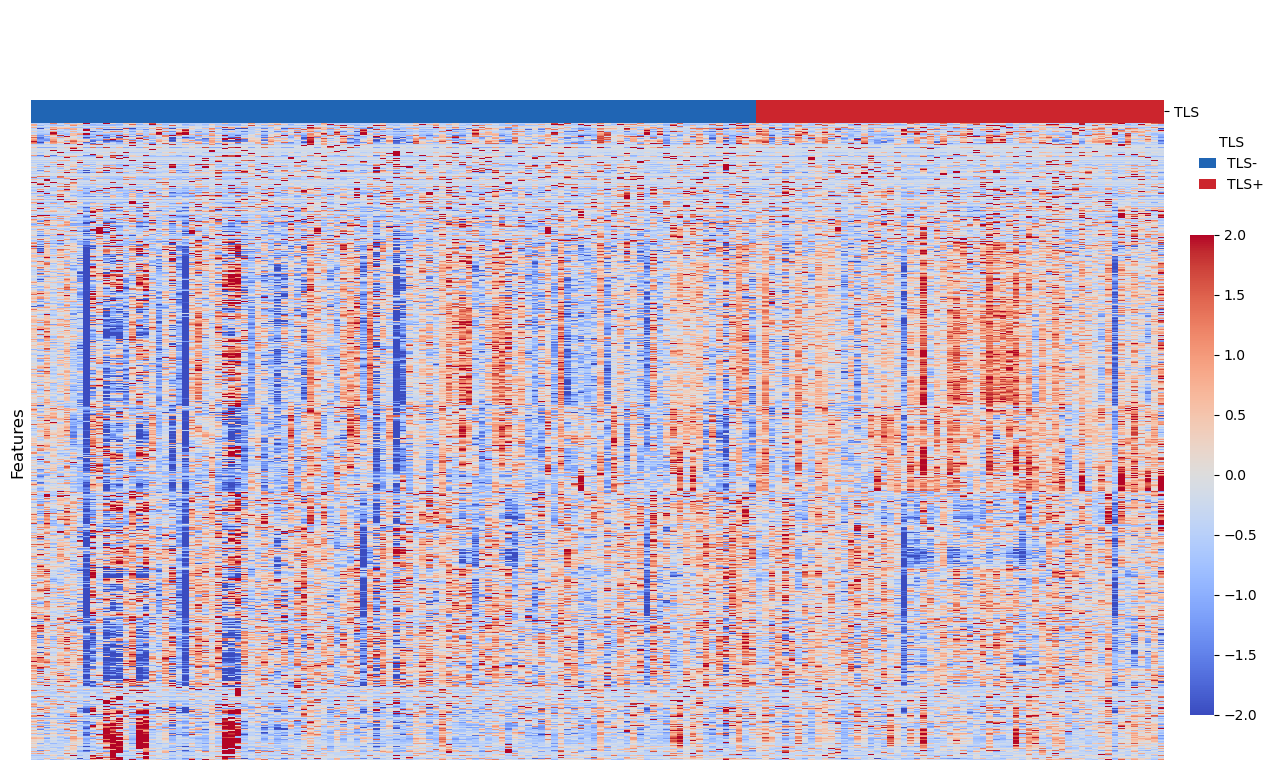

In [40]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Clustermap
g = sns.clustermap(
    mat,
    cmap="coolwarm",
    metric="correlation",
    col_colors=col_colors,
    col_cluster=False,
    row_cluster=True,
    figsize=(12, 8),
    dendrogram_ratio=(0.001, 0.12),   # row dendrogram 幾乎不佔空間，但仍進行 clustering
    cbar_pos=(0.98, 0.1, 0.02, 0.6),  # (left, bottom, width, height)
    vmax=2,
    vmin=-2,
    xticklabels=False,
    yticklabels=False
)

# 隱藏 row dendrogram（不影響 row clustering 的排序結果）
g.ax_row_dendrogram.set_visible(False)

# feature 軸資訊放左邊
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel("Features", fontsize=12)
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.yaxis.tick_left()

# 用 Rectangle 製作正方形 legend
handles = [
    Rectangle((0, 0), 1, 1, facecolor="#2065B4", edgecolor="none", label="TLS-"),
    Rectangle((0, 0), 1, 1, facecolor="#CC252D", edgecolor="none", label="TLS+")
]
legend = g.ax_heatmap.legend(
    handles=handles,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    handlelength=1.2,          # 調整正方形大小
)
#legend.get_title().set_fontsize(12)


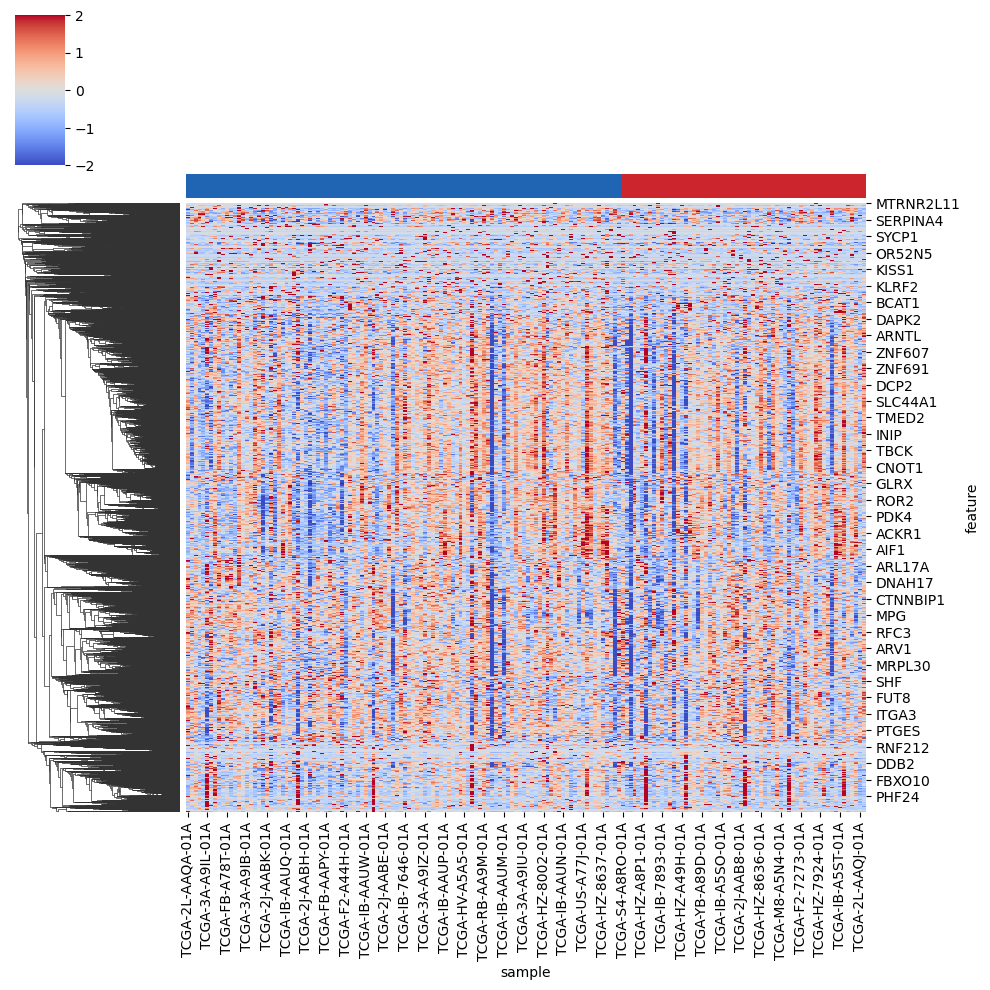

In [95]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
tls_labels = table_scaled.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
mat_sorted = mat.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(mat_sorted, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15),
               vmax=2, vmin=-2, col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

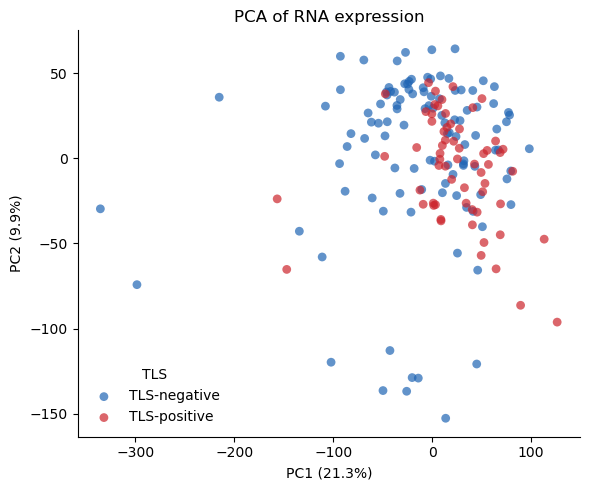

In [100]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA
mat_T = mat.T  # samples × genes
pca = PCA(n_components=2)
pca_result = pca.fit_transform(mat_T)

# 畫圖
fig, ax = plt.subplots(figsize=(6, 5))
tls_series = table_scaled.sample_metadata.loc[mat.columns, "TLS"].astype(int)

for tls_val, color, label in zip([0, 1], ["#2065B4", "#CC252D"], ["TLS-negative", "TLS-positive"]):
    mask = tls_series == tls_val
    ax.scatter(
        pca_result[mask, 0],
        pca_result[mask, 1],
        c=color, label=label, alpha=0.7, s=40, edgecolors="none"
    )

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(title="TLS", frameon=False)
ax.set_title("PCA of RNA expression")
sns.despine()
plt.tight_layout()

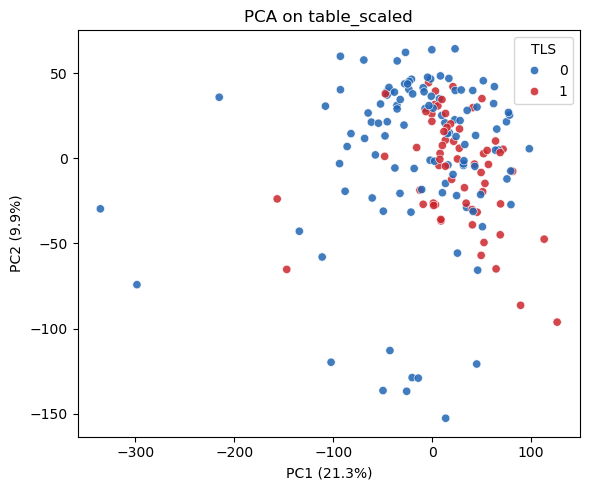

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

X = pd.DataFrame(table_scaled).T  # samples x features
tls = table_scaled.sample_metadata.loc[X.index, "TLS"].astype(int)

# PCA 前再次做健全性清理（避免 NaN/Inf）
X = X.replace([np.inf, -np.inf], np.nan).dropna(axis=0, how="any").dropna(axis=1, how="any")
tls = tls.loc[X.index]

pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X)
pca_df = pd.DataFrame(pcs, columns=["PC1", "PC2"], index=X.index)
pca_df["TLS"] = tls.values

plt.figure(figsize=(6, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="TLS", alpha=0.85,
                palette={0: "#2065B4", 1: "#CC252D"})
plt.title("PCA on table_scaled")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(title="TLS")
plt.tight_layout()

#### Split into train / test dataset
* validation 跟 test dataset 都需要 fit training 的數值

In [12]:
from sklearn.model_selection import train_test_split
X = table.T  # shape: samples × genes
y = table.sample_metadata["TLS"]  # TLS label (0 or 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)

# Add train/test labels to sample_metadata and sort
table.sample_metadata.loc[y_train.index, "split_42"] = "train"
table.sample_metadata.loc[y_test.index, "split_42"] = "test"
table = table.reindex(columns=y_train.index.tolist() + y_test.index.tolist())
table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,0.193330,0.108892,0.197111,0.081749,0.000000,1.081749,0.159887,0.074231,0.075601,0.224411,...,0.158725,0.212881,0.167615,0.057277,0.202136,0.080794,0.157691,0.254836,0.164143,0.423847
A1CF,1.845470,1.654161,1.610228,0.901263,0.743472,3.743623,1.724738,0.750092,0.972913,0.224287,...,1.489851,1.940918,0.909428,1.748332,2.235666,0.809085,1.242511,3.328348,2.549989,4.870113
A2M,7.074512,8.349059,8.484469,7.083435,7.407824,8.176749,9.015322,7.763216,6.653587,8.083053,...,8.409315,9.738109,7.288060,8.467864,8.431143,6.905653,8.867650,8.832984,8.984924,6.833316
A2ML1,0.214374,0.106616,0.064193,2.738833,2.330128,0.091124,2.903347,2.855591,2.494953,4.071891,...,0.849439,0.055890,0.036749,0.042924,0.224040,5.334894,0.550605,2.892391,1.326537,0.064055
A3GALT2,0.247077,0.106482,0.000000,0.424062,0.083656,0.334111,0.297485,0.095992,0.000000,0.000000,...,0.000000,0.271665,0.000000,0.000000,0.197740,0.104471,0.124725,0.294665,0.129876,0.088956
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.057554,0.047399,0.077790,0.069977,0.000000,0.060186,0.000000,0.042644,0.043345,0.080385,...,0.338339,0.202261,0.073820,0.000000,0.067639,0.069152,0.082703,0.023610,0.086240,0.077790
ZYG11B,3.275975,2.897163,3.814253,2.966541,3.095435,3.415867,3.607662,4.441012,3.223531,2.865899,...,4.007196,4.512954,2.519567,4.326257,3.706343,3.238175,3.906265,4.249711,4.175724,3.494441
ZYX,8.287740,7.681170,7.914015,6.952232,7.146677,6.661400,8.084806,7.436792,7.833077,8.464976,...,8.016946,7.971949,8.002050,7.851096,7.523277,7.541456,8.173957,7.587415,7.930510,4.426392


In [12]:
table.to_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite


In [13]:
# 保留在 training validation set 中 high variance 的 features (10606 genes)
train_samples = table.sample_metadata["split_42"] == "train" 
train_table = table.subset(samples=train_samples)

threshold = 0.25
row_var = train_table.var(axis=1)
high_var_rows = row_var[row_var >= threshold].index
train_table = train_table.subset(features=high_var_rows)
train_table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1CF,1.845470,1.654161,1.610228,0.901263,0.743472,3.743623,1.724738,0.750092,0.972913,0.224287,...,1.770491,2.363816,1.077175,1.415975,0.974603,0.734048,1.160146,4.186960,1.398898,1.648373
A2M,7.074512,8.349059,8.484469,7.083435,7.407824,8.176749,9.015322,7.763216,6.653587,8.083053,...,8.398715,9.593737,7.382747,6.919648,7.820449,8.144368,7.819523,9.625054,9.237116,8.575170
A2ML1,0.214374,0.106616,0.064193,2.738833,2.330128,0.091124,2.903347,2.855591,2.494953,4.071891,...,1.230818,1.167486,0.149259,0.354678,0.240742,3.088057,1.604783,0.050049,4.204876,0.850479
A4GALT,4.481635,4.715031,5.866282,4.760998,4.013543,3.631349,4.367189,6.207157,6.016833,8.069617,...,5.680369,5.847433,3.231448,4.019195,5.279820,5.293514,5.893134,4.078499,5.182172,4.335626
A4GNT,1.853557,0.653519,2.656107,3.466653,1.645517,1.254655,4.450934,1.685402,3.775072,0.155102,...,1.457069,0.172999,4.801583,1.796473,0.398022,1.559394,1.348629,5.747793,0.456911,2.148674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZWILCH,3.780058,2.405829,3.057173,2.581303,3.199091,2.017922,3.109327,3.416961,2.935158,3.420981,...,2.961234,3.099497,1.647499,2.450221,3.095773,3.198148,3.813453,3.728269,3.696717,3.152557
ZWINT,5.704111,4.440640,5.094920,4.139134,4.889941,2.189287,4.231763,4.777241,5.351547,5.539019,...,4.698041,4.549300,2.688516,4.450023,4.091548,5.476809,5.943077,5.650061,4.319278,3.328161
ZYG11B,3.275975,2.897163,3.814253,2.966541,3.095435,3.415867,3.607662,4.441012,3.223531,2.865899,...,3.922074,4.164778,3.003656,3.215244,4.125940,3.422650,3.733636,4.364222,4.765922,4.225167


Number of selected features: 10606


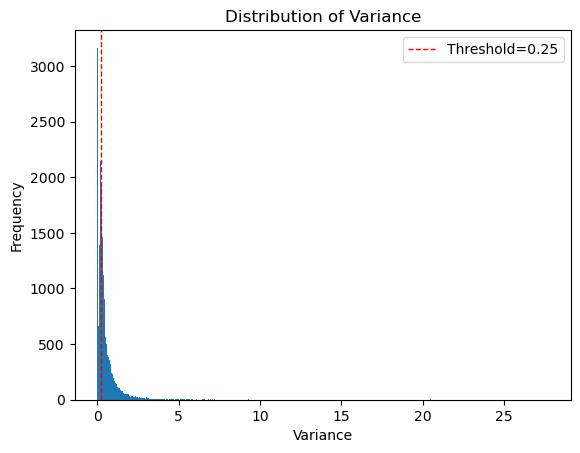

In [13]:
print("Number of selected features:", len(row_var[row_var >= threshold].index))

import matplotlib.pyplot as plt
plt.hist(row_var, bins=500)
plt.xlabel("Variance")
plt.ylabel("Frequency")
plt.title("Distribution of Variance")
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold={threshold}', linewidth=1)
plt.legend()
plt.show()

In [14]:
# 套用在 testing set
test_samples = table.sample_metadata["split_42"] == "test" 
test_table = table.subset(samples=test_samples)

test_table = test_table.subset(features=high_var_rows)
test_table

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1CF,0.247928,2.337740,1.280659,4.721039,0.453228,1.767951,1.822567,0.959993,0.730314,2.305124,...,1.489851,1.940918,0.909428,1.748332,2.235666,0.809085,1.242511,3.328348,2.549989,4.870113
A2M,8.750120,8.007207,8.048475,7.196788,7.804671,8.726109,7.275811,6.583868,7.540605,7.163925,...,8.409315,9.738109,7.288060,8.467864,8.431143,6.905653,8.867650,8.832984,8.984924,6.833316
A2ML1,2.505129,0.227248,6.063958,0.103800,6.151023,0.138159,0.028428,0.492725,5.397255,0.023610,...,0.849439,0.055890,0.036749,0.042924,0.224040,5.334894,0.550605,2.892391,1.326537,0.064055
A4GALT,5.228980,4.950510,4.478409,2.366672,6.155763,4.994340,3.666461,4.031457,5.745867,4.203146,...,4.490153,4.248512,5.423292,3.512391,4.690518,6.971194,4.832055,4.168538,6.184556,2.713234
A4GNT,0.000000,3.102473,2.521629,0.118758,2.889804,0.344374,2.693766,3.471370,0.365581,3.333681,...,1.206331,1.670840,5.165257,5.139122,4.628972,0.175812,2.735587,1.308477,2.717781,0.880255
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZWILCH,3.993566,3.330903,3.533837,2.515485,2.749663,2.454729,3.451831,2.966246,3.225861,2.508936,...,3.655810,3.290011,2.685245,2.989139,2.869062,3.096768,2.973758,3.120004,2.980446,1.210202
ZWINT,5.446885,5.413218,4.929635,3.444283,3.783394,4.181961,5.334676,4.978374,5.256818,4.725289,...,5.361821,4.086521,5.046094,5.434301,4.132330,5.410596,4.007160,5.157323,4.105527,3.298145
ZYG11B,4.010556,3.834833,3.867076,4.254140,3.698663,3.491558,3.572623,2.906352,3.877067,2.963049,...,4.007196,4.512954,2.519567,4.326257,3.706343,3.238175,3.906265,4.249711,4.175724,3.494441


In [10]:
# 展示用
# 對 training validation dataset 進行 z-score normalization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train_scaled = pd.DataFrame(scaler.fit_transform(train_table.T).T, index=train_table.index, columns=train_table.columns)
train_scaled = PivotTable(train_scaled)
train_scaled.feature_metadata = train_table.feature_metadata
train_scaled.sample_metadata = train_table.sample_metadata
train_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1CF,0.203083,0.027604,-0.012694,-0.662996,-0.807730,1.944174,0.092341,-0.801658,-0.597274,-1.283955,...,0.134308,0.678539,-0.501640,-0.190873,-0.595724,-0.816374,-0.425534,2.350827,-0.206538,0.022295
A2M,-1.085711,0.119601,0.247656,-1.077273,-0.770504,-0.043348,0.749672,-0.434418,-1.483770,-0.131955,...,0.166560,1.296667,-0.794219,-1.232163,-0.380294,-0.073970,-0.381169,1.326282,0.959418,0.333430
A2ML1,-0.634618,-0.700016,-0.725763,0.897483,0.649439,-0.709418,0.997327,0.968344,0.749471,1.706519,...,-0.017736,-0.056172,-0.674136,-0.549467,-0.618615,1.109428,0.209225,-0.734347,1.787228,-0.248564
A4GALT,-0.225822,0.011578,1.182577,0.058333,-0.701943,-1.090693,-0.342230,1.529299,1.335710,3.423707,...,0.993475,1.163405,-1.497454,-0.696194,0.586056,0.599984,1.209890,-0.635873,0.486732,-0.374335
A4GNT,-0.194843,-0.919685,0.289911,0.779494,-0.320502,-0.556589,1.374015,-0.296411,0.965783,-1.220737,...,-0.434327,-1.209926,1.585813,-0.229322,-1.074009,-0.372521,-0.499827,2.157339,-1.038439,-0.016587
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZWILCH,1.374265,-0.888259,0.184111,-0.599359,0.417764,-1.526907,0.269977,0.776464,-0.016774,0.783082,...,0.026158,0.253793,-2.136770,-0.815171,0.247661,0.416212,1.429246,1.288999,1.237053,0.341150
ZWINT,1.441958,-0.081653,0.707339,-0.445237,0.460155,-2.796544,-0.333537,0.324251,1.016803,1.242875,...,0.228744,0.049379,-2.194527,-0.070338,-0.502621,1.167856,1.730125,1.376779,-0.228002,-1.423183
ZYG11B,-0.744612,-1.379208,0.157124,-1.262984,-1.047058,-0.510263,-0.188963,1.207087,-0.832469,-1.431583,...,0.337749,0.744333,-1.200808,-0.846351,0.679271,-0.498899,0.022073,1.078447,1.751384,0.845498


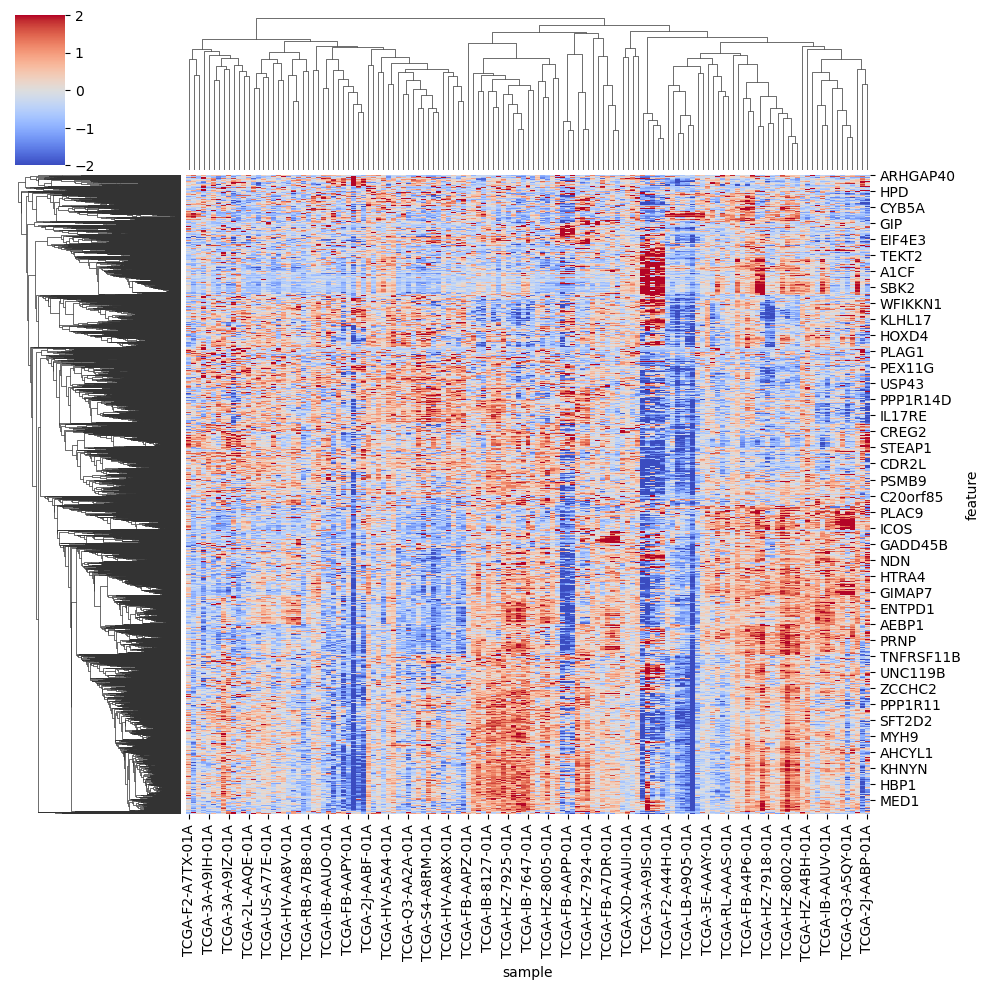

In [12]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(train_scaled, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15), vmax=2, vmin=-2)

<Axes: xlabel='sample', ylabel='feature'>

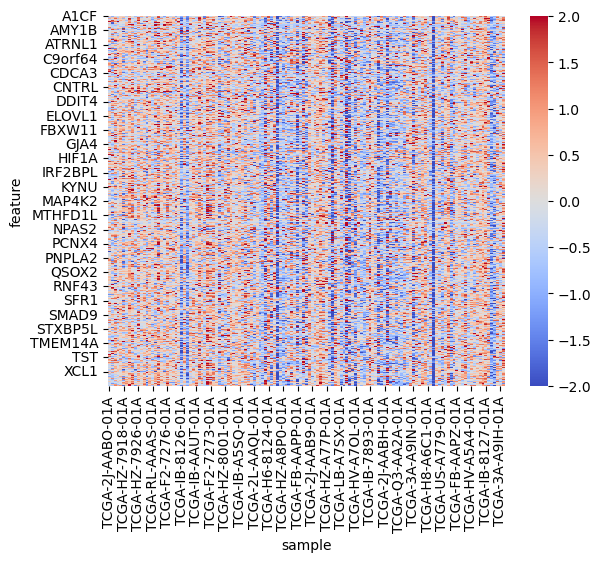

In [19]:
sns.heatmap(train_scaled.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm", vmax=2, vmin=-2)

Text(-2.0828333333333386, 0.5, 'Genes')

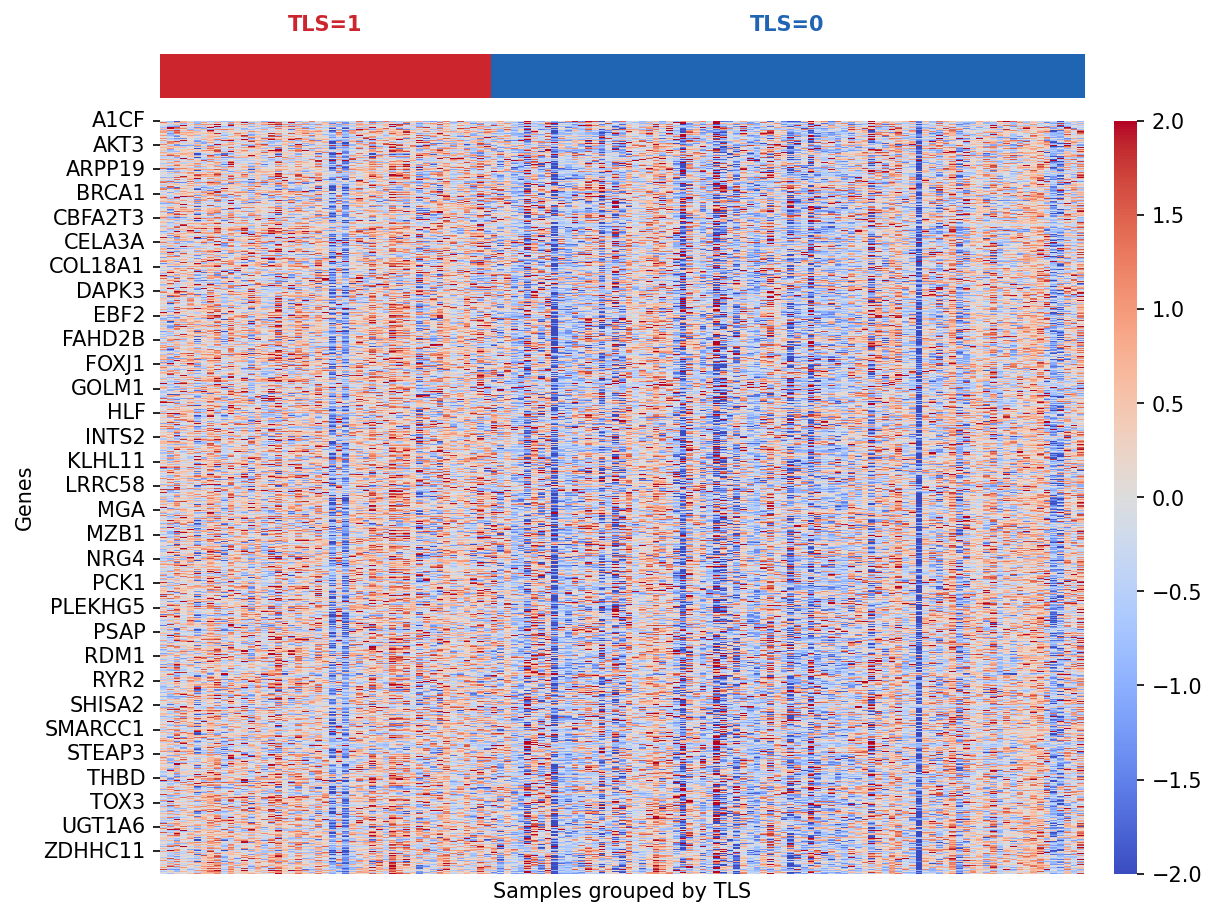

In [27]:
from matplotlib.colors import ListedColormap

ordered = train_scaled.order(group_col="TLS", group_order=[1, 0])
tls_labels = ordered.sample_metadata.loc[ordered.columns, "TLS"].astype(int).values

fig = plt.figure(
    figsize=(8, 6),
    dpi=150,
    constrained_layout=True
 )
gs = fig.add_gridspec(
    nrows=2, ncols=2,
    height_ratios=[0.35, 6],
    width_ratios=[40, 1],
    hspace=0.02,
    wspace=0.05
 )
ax_top = fig.add_subplot(gs[0, 0])
ax = fig.add_subplot(gs[1, 0])
cax = fig.add_subplot(gs[1, 1])

# 上方 TLS 色帶
tls_cmap = ListedColormap(["#2065B4", "#CC252D"])  # 0: blue, 1: red
ax_top.imshow(tls_labels[np.newaxis, :], aspect="auto", cmap=tls_cmap, vmin=0, vmax=1)
ax_top.set_xticks([])
ax_top.set_yticks([])
for spine in ax_top.spines.values():
    spine.set_visible(False)

sns.heatmap(
    ordered,
    cmap="coolwarm",
    vmax=2,
    vmin=-2,
    xticklabels=False,
    ax=ax,
    cbar_ax=cax
 )

split_idx = int((tls_labels == 1).sum())
# if 0 < split_idx < ordered.shape[1]:
#     ax.axvline(split_idx, color="black", linewidth=2)
#     ax_top.axvline(split_idx - 0.5, color="black", linewidth=2)

# 在色帶上方直接標示 TLS 區段
n_samples = ordered.shape[1]
n_tls1 = split_idx
n_tls0 = n_samples - n_tls1
if n_tls1 > 0:
    ax_top.text((n_tls1 - 1) / 2, -0.95, "TLS=1", color="#CC252D", ha="center", va="bottom", fontsize=10, fontweight="bold", clip_on=False)
if n_tls0 > 0:
    ax_top.text(n_tls1 + (n_tls0 - 1) / 2, -0.95, "TLS=0", color="#2065B4", ha="center", va="bottom", fontsize=10, fontweight="bold", clip_on=False)

ax.set_xlabel("Samples grouped by TLS")
ax.set_ylabel("Genes")
#cax.set_ylabel("Z-score", rotation=270, labelpad=14)

In [16]:
# testing dataset 進行 min-max normalization
test_scaled = pd.DataFrame(scaler.transform(test_table.T).T, index=test_table.index, columns=test_table.columns)
test_scaled = PivotTable(test_scaled)
test_scaled.feature_metadata = test_table.feature_metadata
test_scaled.sample_metadata = test_table.sample_metadata
test_scaled

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1CF,0.046162,0.454437,0.247921,0.920049,0.086271,0.343121,0.353791,0.185275,0.140403,0.448065,...,0.288790,0.376912,0.175396,0.339288,0.434496,0.155793,0.240469,0.647967,0.495903,0.949173
A2M,0.745556,0.622785,0.629605,0.488858,0.589315,0.741588,0.501917,0.387569,0.545676,0.483427,...,0.689236,0.908828,0.503941,0.698911,0.692843,0.440746,0.764979,0.759250,0.784359,0.428792
A2ML1,0.313812,0.028467,0.759618,0.013003,0.770524,0.017307,0.003561,0.061723,0.676102,0.002958,...,0.106407,0.007001,0.004604,0.005377,0.028065,0.668290,0.068973,0.362323,0.166172,0.008024
A4GALT,0.516018,0.468573,0.388137,0.028343,0.673921,0.476040,0.249799,0.311986,0.604084,0.341238,...,0.390138,0.348968,0.549124,0.223549,0.424276,0.812853,0.448390,0.335342,0.678827,0.087390
A4GNT,0.000000,0.474617,0.385759,0.018168,0.442083,0.052682,0.412093,0.531051,0.055927,0.509987,...,0.184545,0.255606,0.790182,0.786184,0.708141,0.026896,0.418491,0.200171,0.415767,0.134662
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZWILCH,0.794853,0.617974,0.672142,0.400322,0.462829,0.384105,0.650253,0.520640,0.589936,0.398574,...,0.704699,0.607060,0.445634,0.526750,0.494699,0.555479,0.522645,0.561681,0.524430,0.051914
ZWINT,0.837382,0.828739,0.704593,0.323273,0.410330,0.512650,0.808575,0.717106,0.788588,0.652133,...,0.815544,0.488148,0.734491,0.834151,0.499909,0.828066,0.467775,0.763045,0.493028,0.285756
ZYG11B,0.724023,0.677010,0.685637,0.789192,0.640579,0.585170,0.606859,0.428604,0.688310,0.443773,...,0.723124,0.858435,0.325124,0.808486,0.642634,0.517380,0.696121,0.788007,0.768213,0.585942


Zero variance rows: 1
Zero variance cols: 0


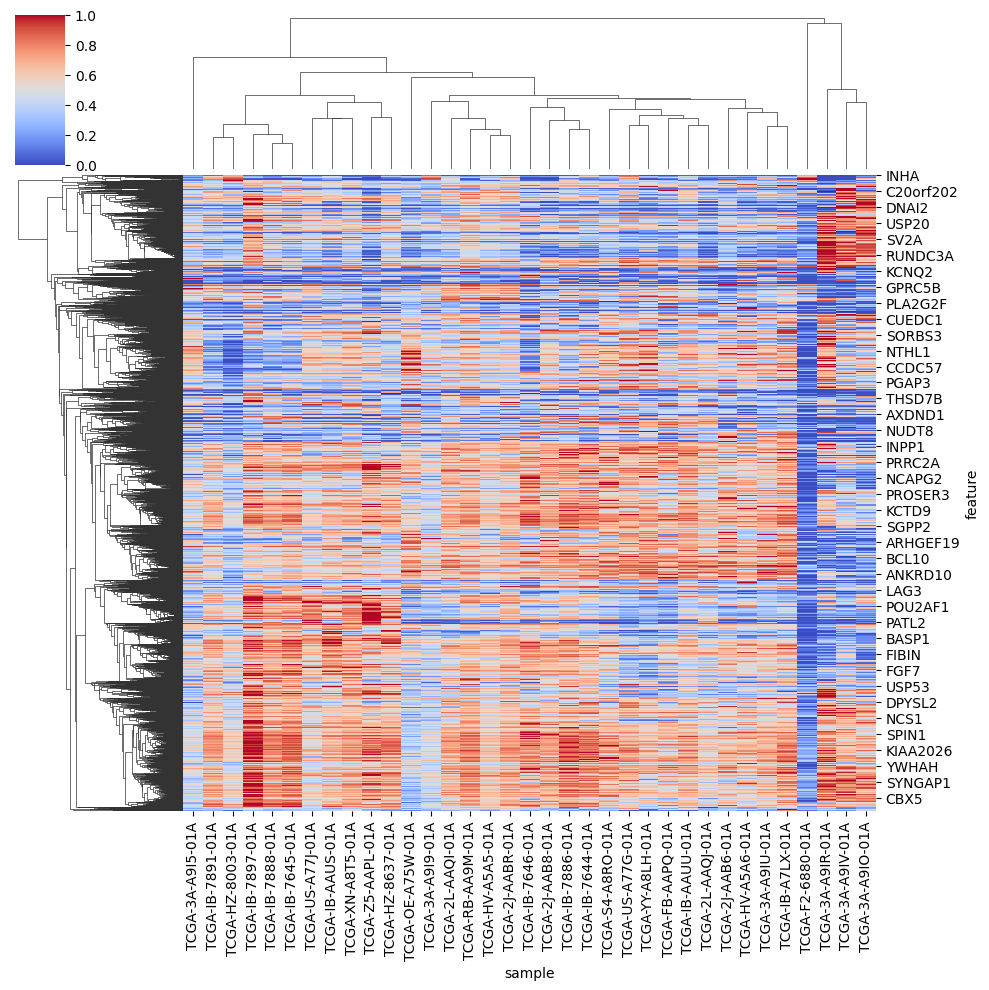

In [69]:
# 找 variance = 0 的 row/col
zero_var_rows = test_scaled.var(axis=1) == 0
zero_var_cols = test_scaled.var(axis=0) == 0
print("Zero variance rows:", zero_var_rows.sum())
print("Zero variance cols:", zero_var_cols.sum())
test_scaled_clean = test_scaled.loc[~zero_var_rows, ~zero_var_cols]

import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(test_scaled_clean, cmap="coolwarm", metric="correlation", vmin=0, vmax=1, cbar_pos=(0.02, 0.83, 0.05, 0.15))  # test_scaled 的範圍不會剛好在0-1之間

<Axes: xlabel='sample', ylabel='feature'>

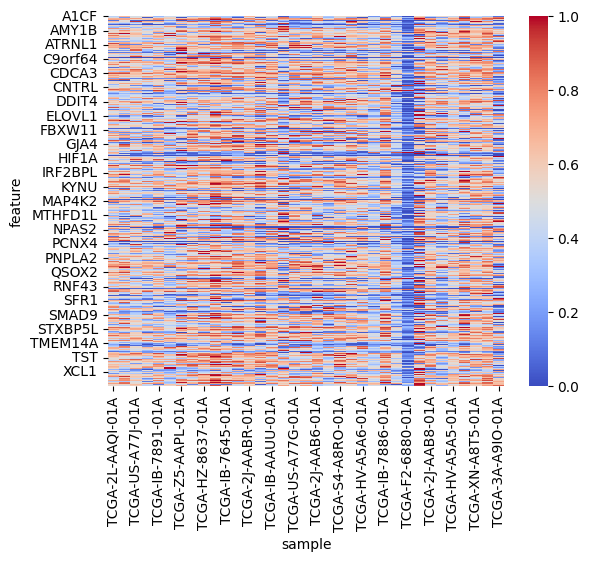

In [70]:
sns.heatmap(test_scaled.order(group_col="TLS", group_order=[1, 0]), vmin=0, vmax=1, cmap="coolwarm")

In [22]:
# All features performance
all_features = train_table.index
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(train_table, test_table, top_features=all_features)
print(report)

Selected top 10606 features
Best cutoff in AUROC: 0.67
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.500 | Accuracy: 0.714 | AUC: 0.752 | AUPRC: 0.721
              precision    recall  f1-score   support

TLS-negative      0.714     0.909     0.800        22
TLS-positive      0.714     0.385     0.500        13

    accuracy                          0.714        35
   macro avg      0.714     0.647     0.650        35
weighted avg      0.714     0.714     0.689        35



#### mRMR

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from mrmr import mrmr_classif
from sklearn.metrics import roc_auc_score

X = pd.DataFrame(train_table.T)
y = pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"])
K_list = [50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300]  # 你要選的特徵數

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []
std_auc_scores = []
best_auc = 0
best_k = None

for K in K_list:
    auc_scores_K = []
    for train_idx, val_idx in outer_cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # 只用 training fold 做 mRMR
        selected_features = mrmr_classif(X=X_train, y=y_train, K=K)
        X_train_sel = X_train[selected_features]
        X_val_sel = X_val[selected_features]
        
        clf = RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_split=10,  # 分裂內部節點所需的最小樣本數 (defalut=2)
            min_samples_leaf=5,  # 葉節點所需的最小樣本數 (defalut=1)
            class_weight="balanced",
            random_state=42,
            n_jobs=10
        )
        clf.fit(X_train_sel, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val_sel)[:,1])
        auc_scores_K.append(auc)
    
    mean_auc = np.mean(auc_scores_K)
    std_auc = np.std(auc_scores_K)
    auc_scores.append(mean_auc)
    std_auc_scores.append(std_auc)
    print(f"K={K}, mean AUC={mean_auc:.3f}, std={std_auc:.3f}")
    
    if mean_auc > best_auc:
        best_auc = mean_auc
        best_k = K

print(f"Best K: {best_k}, AUC: {best_auc:.3f}")

100%|██████████| 50/50 [00:27<00:00,  1.79it/s]


K=50, mean AUC=0.810, std=0.074


100%|██████████| 75/75 [00:44<00:00,  1.69it/s]


K=75, mean AUC=0.812, std=0.082


100%|██████████| 100/100 [00:59<00:00,  1.69it/s]


...

K=250, mean AUC=0.814, std=0.083


100%|██████████| 275/275 [02:49<00:00,  1.62it/s]


K=275, mean AUC=0.820, std=0.086


100%|██████████| 300/300 [03:44<00:00,  1.34it/s]


K=300, mean AUC=0.817, std=0.083
Best K: 150, AUC: 0.824


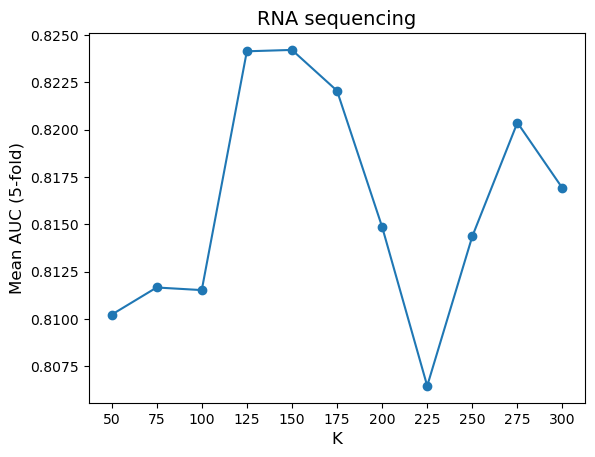

In [18]:
plt.plot(K_list, auc_scores, '-o')
plt.xlabel("K", fontsize=12)
plt.ylabel("Mean AUC (5-fold)", fontsize=12)
plt.xticks(K_list)
plt.title("RNA sequencing", fontsize=14)
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/mRMR_rna.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Text(0.5, 1.0, 'Mean AUC with Std (5-fold)')

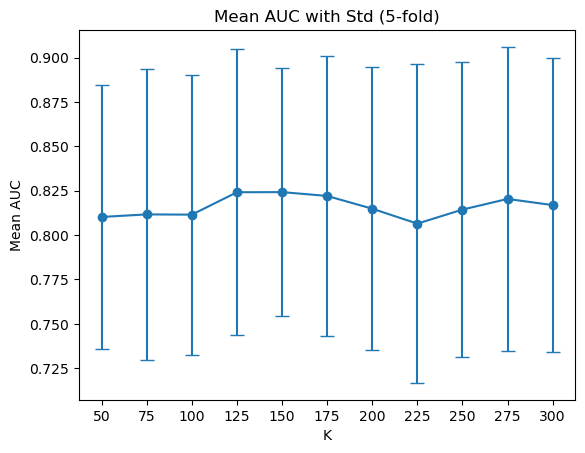

In [20]:
plt.errorbar(K_list, auc_scores, yerr=std_auc_scores, fmt='-o', capsize=5)
plt.xlabel("K")
plt.ylabel("Mean AUC")
plt.xticks(K_list)
plt.title("Mean AUC with Std (5-fold)")

In [23]:
from mrmr import mrmr_classif

top_features = mrmr_classif(
    X=pd.DataFrame(train_table.T),
    y=pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"]),
    K=best_k  # 要選幾個
)

np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_rna_mrmr.npy", top_features)
print(top_features)

100%|██████████| 150/150 [01:33<00:00,  1.60it/s]

['CR2', 'NOMO2', 'H4C5', 'HMGCS2', 'CCL17', 'CXCL13', 'GPR18', 'MT1H', 'TAGAP', 'MS4A1', 'ANKRD1', 'CCR2', 'PLA2G2D', 'FCMR', 'ABI3BP', 'KCNA3', 'POMZP3', 'CCL19', 'CCR4', 'CTSV', 'IKZF1', 'PTPRC', 'WDFY4', 'TLR10', 'EOMES', 'CD180', 'RIPOR2', 'SOX15', 'GAPT', 'MS4A14', 'RPS10', 'GZMK', 'VPREB3', 'SLC20A2', 'CCR7', 'CD22', 'IRF4', 'TDRD1', 'SEL1L', 'CD1D', 'CD79B', 'IGF2BP1', 'CLC', 'FCRLA', 'ABCA6', 'SPN', 'FCER2', 'RGS20', 'FMO2', 'CD79A', 'PHYHIPL', 'LY9', 'ADGRE2', 'SIT1', 'CCL22', 'WASHC1', 'MGAT4A', 'CLEC17A', 'CD101', 'THEMIS', 'SCIMP', 'IGSF9B', 'BTLA', 'CD48', 'ITGA4', 'CR1', 'CD19', 'SLCO3A1', 'SELL', 'MPEG1', 'FDCSP', 'SLC2A9', 'TLR6', 'ANGPTL7', 'CD3G', 'CD8B', 'PAX5', 'PIK3CD', 'MOK', 'DENND4A', 'FYB1', 'NLRC3', 'TRAT1', 'MUC16', 'LTA', 'SELP', 'MT-CO3', 'TCL1A', 'CD28', 'ANKRD33B', 'BIN2', 'FGF19', 'CD27', 'DOCK2', 'FCRL1', 'MT-CO2', 'NUGGC', 'TRAF3IP3', 'MT1F', 'ITGAL', 'IL16', 'WASHC5', 'RCSD1', 'LAX1', 'SP140', 'CAMK1D', 'PLEK', 'VPS9D1', 'FCRL3', 'CD2', 'FLI1', 'CD83'

#### Feature Importance (Run 100 times)

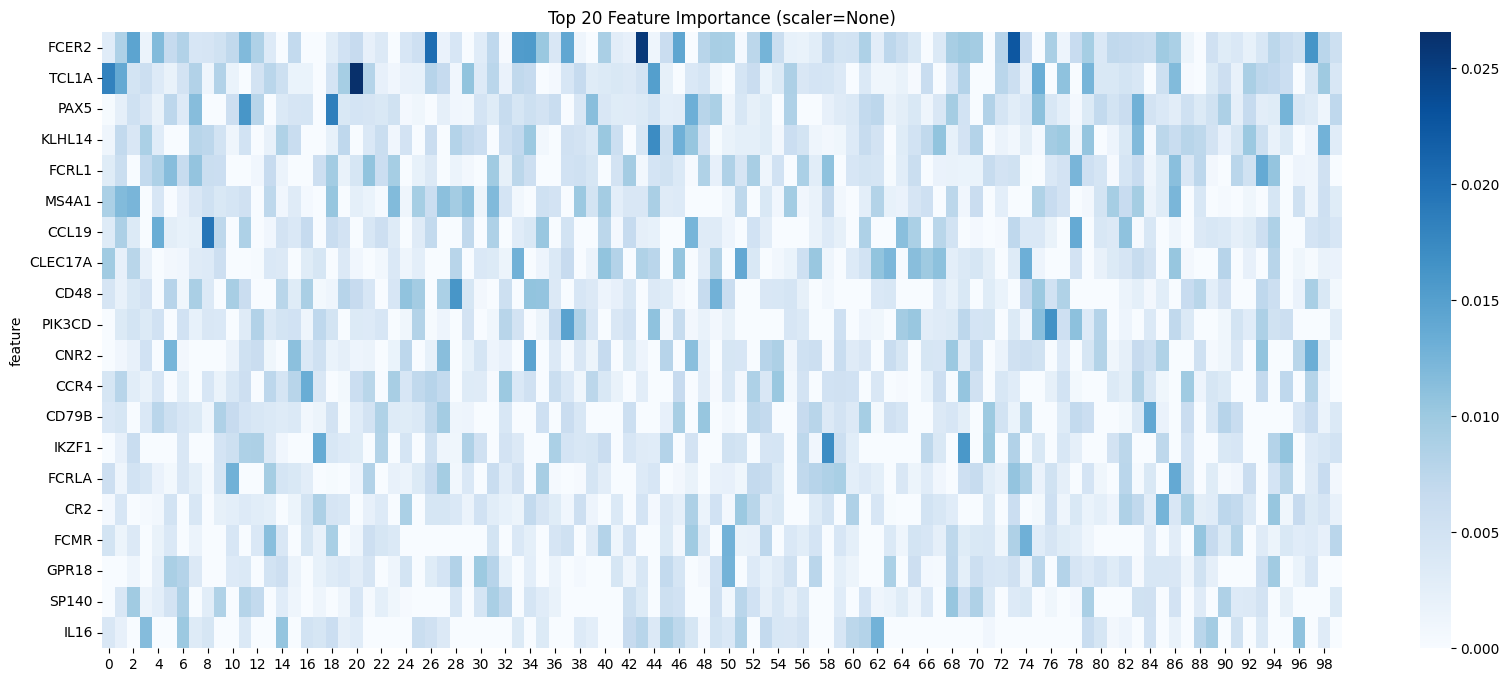

feature
FCER2      0.006142
TCL1A      0.004768
PAX5       0.004539
KLHL14     0.004444
FCRL1      0.004253
MS4A1      0.003999
CCL19      0.003607
CLEC17A    0.003583
CD48       0.003551
PIK3CD     0.003523
CNR2       0.003506
CCR4       0.003457
CD79B      0.003448
IKZF1      0.003389
FCRLA      0.003339
CR2        0.003302
FCMR       0.003036
GPR18      0.003007
SP140       0.00271
IL16       0.002704
dtype: object


In [ ]:
from model_utils import run_feature_importance
global_importance = run_feature_importance(train_table, run_seeds=100,
                                           save_path="/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/rna_importance.csv", plot_top=20)
print(global_importance.head(20))

#### Choose cutoff for selected features

In [ ]:
# import pandas as pd
# importance_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/rna_importance.csv", index_col=0)
# global_importance = importance_df.mean(axis=1).sort_values(ascending=False)
# global_importance = global_importance.astype(object)   # 將資料型別轉換為 object (防止 knee_x 出現小數點)
# print(global_importance.head(20))

feature
FCER2      0.006142
TCL1A      0.004768
PAX5       0.004539
KLHL14     0.004444
FCRL1      0.004253
MS4A1      0.003999
CCL19      0.003607
CLEC17A    0.003583
CD48       0.003551
PIK3CD     0.003523
CNR2       0.003506
CCR4       0.003457
CD79B      0.003448
IKZF1      0.003389
FCRLA      0.003339
CR2        0.003302
FCMR       0.003036
GPR18      0.003007
SP140       0.00271
IL16       0.002704
dtype: object


Elbow point (Feature top n): 153


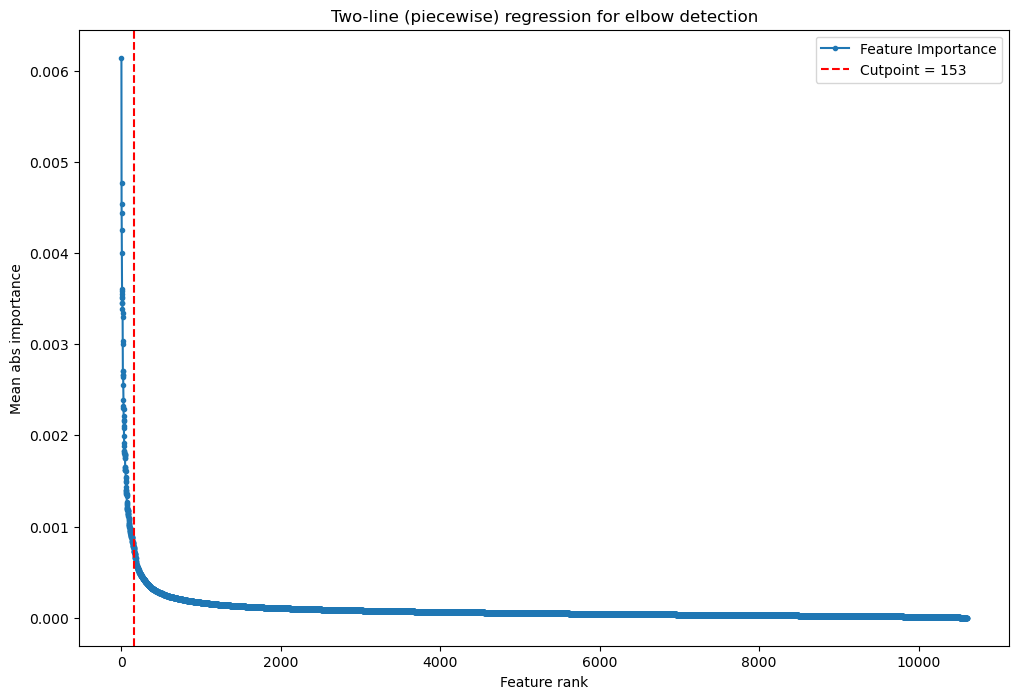

In [7]:
from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)

In [15]:
top_features = global_importance.head(knee_x).index
#np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_rna.npy", top_features)
print(top_features)

# top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_rna.npy", allow_pickle=True)
# top_features

Index(['FCER2', 'TCL1A', 'PAX5', 'KLHL14', 'FCRL1', 'MS4A1', 'CCL19',
       'CLEC17A', 'CD48', 'PIK3CD',
       ...
       'TIGIT', 'SP110', 'RCSD1', 'ABCA6', 'CAMK4', 'IQGAP1', 'CCL21',
       'P2RY12', 'SLCO3A1', 'LPAR1'],
      dtype='object', name='feature', length=153)


In [46]:
top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_rna.npy", allow_pickle=True)
top_features

array(['FCER2', 'TCL1A', 'PAX5', 'KLHL14', 'FCRL1', 'MS4A1', 'CCL19',
       'CLEC17A', 'CD48', 'PIK3CD', 'CNR2', 'CCR4', 'CD79B', 'IKZF1',
       'FCRLA', 'CR2', 'FCMR', 'GPR18', 'SP140', 'IL16', 'TLR10', 'CD22',
       'CD19', 'BLK', 'CXCL13', 'NIBAN3', 'CCR7', 'BTLA', 'LTA',
       'TRAF3IP3', 'SIT1', 'ADRB2', 'TAGAP', 'ADAMTS3', 'FCRL3', 'NLRC3',
       'VPREB3', 'P2RX5', 'MPEG1', 'HLA-DOA', 'ETS1', 'MAP4K1', 'ICOS',
       'PLA2G2D', 'RIPOR2', 'WDFY4', 'GZMK', 'FCRL2', 'CORO1A', 'CD28',
       'CCR2', 'TNFRSF13C', 'C21orf91', 'SCARA5', 'CYBRD1', 'CD37',
       'ICAM3', 'LTB', 'ITGAL', 'CD180', 'TNFRSF13B', 'FDCSP', 'IRF4',
       'KBTBD8', 'CD79A', 'CD52', 'STAP1', 'F2R', 'TRAT1', 'ITK', 'PLEK',
       'SEPTIN1', 'SLAMF1', 'EOMES', 'CD3G', 'TESPA1', 'ABI3BP', 'IKZF3',
       'KCNA3', 'GAPT', 'IRF8', 'GPR171', 'TNFSF8', 'MT-ND3', 'NUGGC',
       'ARHGAP30', 'PTPRC', 'THEMIS', 'ARHGAP25', 'LY9', 'NIN', 'HVCN1',
       'LIMD2', 'CD3E', 'BIN2', 'FLVCR2', 'LAX1', 'CD209', 'CD6',
      

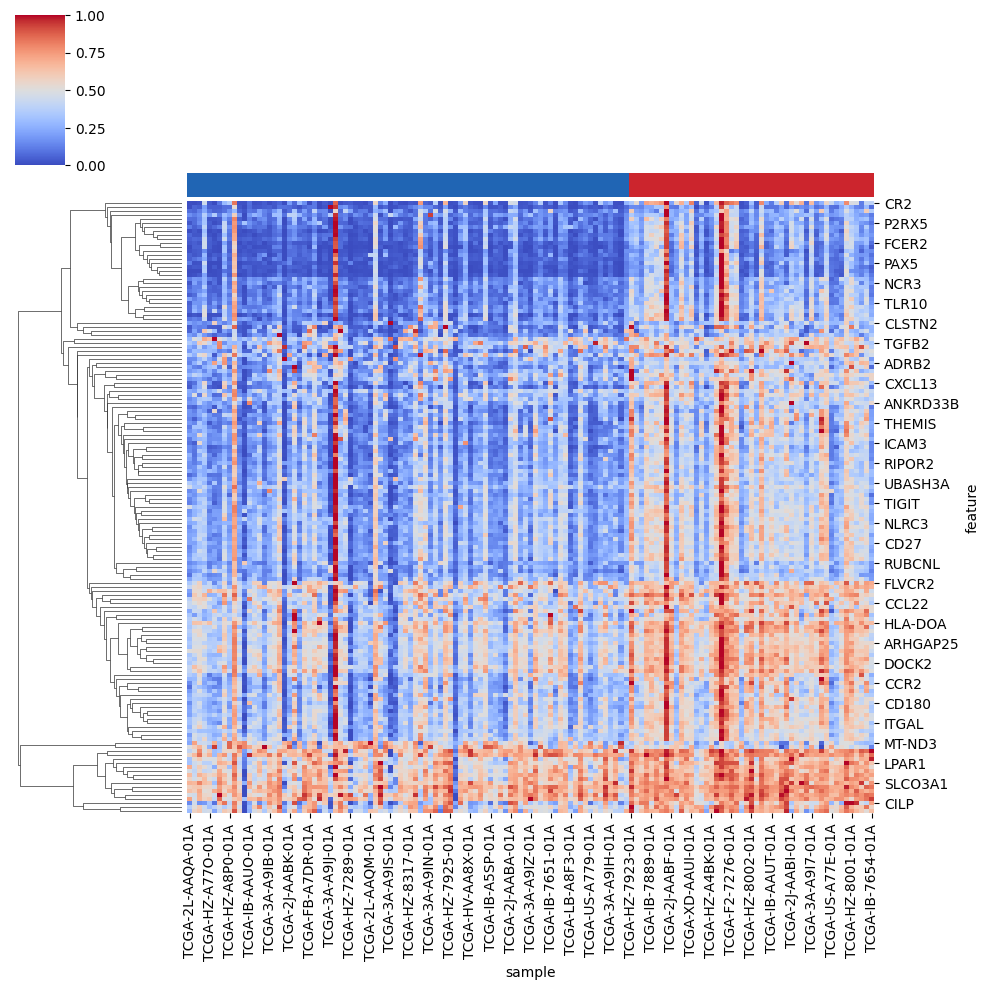

In [20]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
train_subseted = train_scaled.subset(features=top_features)
tls_labels = train_subseted.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_subseted_sorted = train_subseted.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_subseted_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

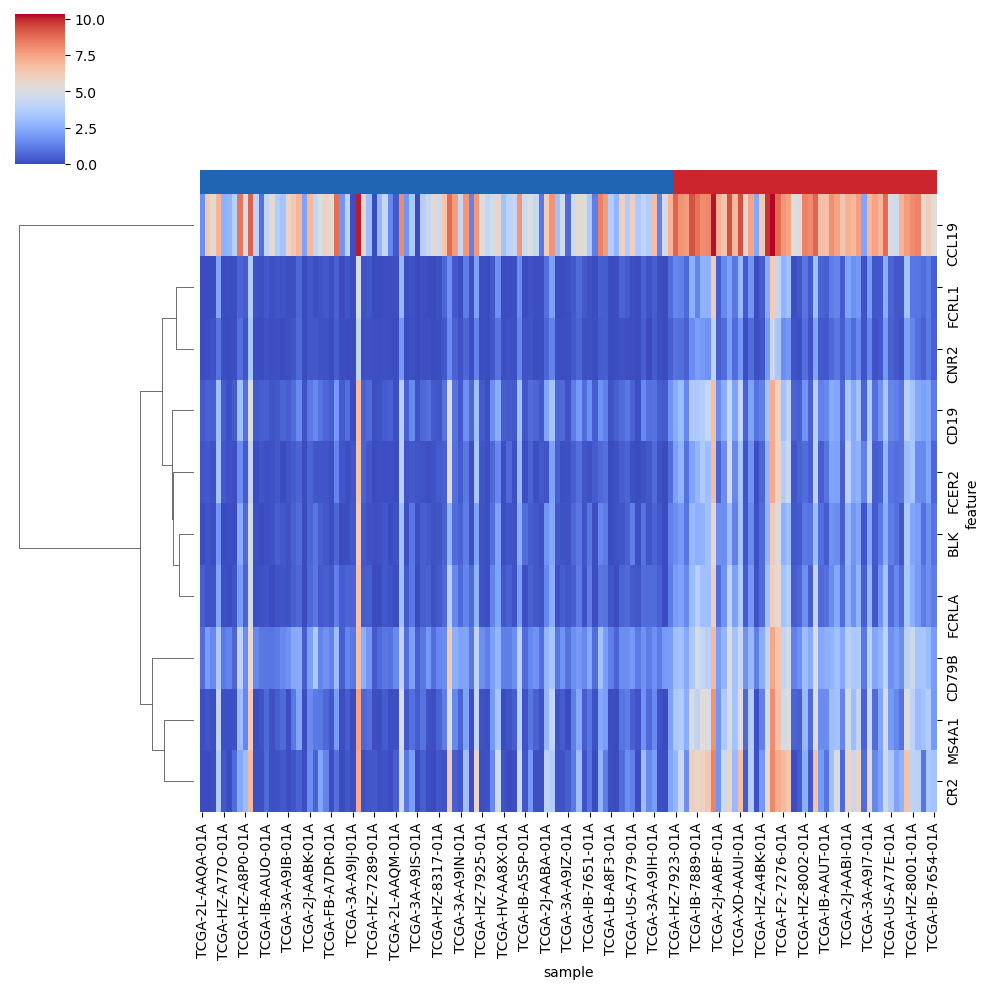

In [ ]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
common_features = ['FCER2','FCRL1','BLK','CNR2','MS4A1','FCRLA','CR2','CD79B','CCL19','CD19']
train_subseted = train_scaled.subset(features=common_features)
tls_labels = train_subseted.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_subseted_sorted = train_subseted.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_subseted_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

In [21]:
train_table.subset(features=top_features).feature_metadata

,additional_info,baseMean,change,chr,end,ensg_name,gene_id,gene_name,gene_name_x,gene_name_y,...,lfcSE,log2FoldChange,padj,phase,pvalue,score,source,start,stat,strand
feature,,,,,,,,,,,,,,,,,,,,,
FCER2,"gene_id ""ENSG00000104921.15""; gene_type ""prote...",208.569200,UP,chr19,7702146.0,ENSG00000104921.15,ENSG00000104921.15,FCER2,FCER2,FCER2,...,0.391237,2.919061,6.034729e-11,.,8.579731e-14,.,HAVANA,7688758.0,7.461109,-
TCL1A,"gene_id ""ENSG00000100721.11""; gene_type ""prote...",266.360272,UP,chr14,95714196.0,ENSG00000100721.11,ENSG00000100721.11,TCL1A,TCL1A,TCL1A,...,0.440108,3.002299,3.201251e-09,.,8.995131e-12,.,HAVANA,95709947.0,6.821729,-
PAX5,"gene_id ""ENSG00000196092.14""; gene_type ""prote...",313.603053,UP,chr9,37034268.0,ENSG00000196092.14,ENSG00000196092.14,PAX5,PAX5,PAX5,...,0.338025,2.602142,1.457331e-11,.,1.381284e-14,.,HAVANA,36833269.0,7.698078,-
KLHL14,"gene_id ""ENSG00000197705.10""; gene_type ""prote...",37.201161,UP,chr18,32773023.0,ENSG00000197705.10,ENSG00000197705.10,KLHL14,KLHL14,KLHL14,...,0.283167,1.690098,2.525494e-07,.,2.393707e-09,.,HAVANA,32672673.0,5.968550,-
FCRL1,"gene_id ""ENSG00000163534.15""; gene_type ""prote...",144.910576,UP,chr1,157820120.0,ENSG00000163534.15,ENSG00000163534.15,FCRL1,FCRL1,FCRL1,...,0.375917,3.166122,1.751111e-13,.,3.688297e-17,.,HAVANA,157794403.0,8.422406,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IQGAP1,"gene_id ""ENSG00000140575.13""; gene_type ""prote...",15133.846543,NOT,chr15,90502239.0,ENSG00000140575.13,ENSG00000140575.13,IQGAP1,IQGAP1,IQGAP1,...,0.084064,0.223885,2.740365e-02,.,7.738594e-03,.,HAVANA,90388242.0,2.663267,+
CCL21,"gene_id ""ENSG00000137077.8""; gene_type ""protei...",2403.919276,UP,chr9,34710136.0,ENSG00000137077.8,ENSG00000137077.8,CCL21,CCL21,CCL21,...,0.266859,1.582943,2.949094e-07,.,2.997079e-09,.,HAVANA,34709005.0,5.931758,-
P2RY12,"gene_id ""ENSG00000169313.10""; gene_type ""prote...",57.922112,UP,chr3,151384753.0,ENSG00000169313.10,ENSG00000169313.10,P2RY12,P2RY12,P2RY12,...,0.203075,1.196990,3.627106e-07,.,3.762518e-09,.,HAVANA,151336843.0,5.894309,-


In [22]:
selected_type = (
    pd.Series(train_table.subset(features=top_features).feature_metadata['change'])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(selected_type)

change
UP     96
NOT    57
Name: count, dtype: int64


#### Model Evaluation

In [24]:
# Evaluation on test dataset
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(train_table, test_table, top_features=top_features)
print(report)

Selected top 150 features
Best cutoff in AUROC: 0.63
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.636 | Accuracy: 0.771 | AUC: 0.881 | AUPRC: 0.827
              precision    recall  f1-score   support

TLS-negative      0.769     0.909     0.833        22
TLS-positive      0.778     0.538     0.636        13

    accuracy                          0.771        35
   macro avg      0.774     0.724     0.735        35
weighted avg      0.772     0.771     0.760        35

